In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
print("pandas version:", pd.__version__)


pandas version: 2.3.3


In [8]:
ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
if not (ROOT / "requirements.txt").exists():
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")

RAW_DIR = ROOT / "data" / "raw" / "fred"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
for folder in (RAW_DIR, INTERIM_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)

Project root: /Users/manishsm/Desktop/Fall 2026/Financial Econometrics/Final Project/Econ524FinalProject


Dates and series codes

In [9]:
RAW_START = "2009-12-01"      # One extra month for Z3's first difference
SAMPLE_START = "2010-01-01"
SAMPLE_END = "2026-10-31"     # Last complete calendar month as of 2026-11-25

SERIES_CODES = ["T10Y2Y", "BAA10YM", "AAA10YM", "UNRATE"]
print("Downloading:", ", ".join(SERIES_CODES))

Downloading: T10Y2Y, BAA10YM, AAA10YM, UNRATE


Download each FRED series


In [10]:
def download_fred_csv(series_code, start, end):
    url = (
        "https://fred.stlouisfed.org/graph/fredgraph.csv"
        f"?id={series_code}&cosd={start}&coed={end}"
    )
    observations = pd.read_csv(url, na_values=["."])
    date_col = "observation_date" if "observation_date" in observations.columns else "DATE"
    if date_col not in observations.columns or series_code not in observations.columns:
        raise ValueError(f"Unexpected FRED CSV format for {series_code}: {observations.columns.tolist()}")
    observations[date_col] = pd.to_datetime(observations[date_col])
    observations[series_code] = pd.to_numeric(observations[series_code], errors="coerce")
    observations = observations.set_index(date_col).sort_index()
    observations.index.name = "date"
    return observations.loc[start:end, [series_code]]

raw = {}
for series_code in SERIES_CODES:
    try:
        observations = download_fred_csv(series_code, RAW_START, SAMPLE_END)
    except Exception as exc:
        raise RuntimeError(f"Could not download {series_code} from FRED") from exc

    if observations.empty:
        raise ValueError(f"FRED returned no observations for {series_code}")

    observations.to_csv(RAW_DIR / f"{series_code}.csv", date_format="%Y-%m-%d")
    raw[series_code] = observations[series_code]

    print(f"{series_code}: {len(observations):,} records; "
          f"{observations.index.min():%Y-%m-%d} to "
          f"{observations.index.max():%Y-%m-%d}")


T10Y2Y: 4,414 records; 2009-12-01 to 2026-10-30
BAA10YM: 203 records; 2009-12-01 to 2026-10-01
AAA10YM: 203 records; 2009-12-01 to 2026-10-01
UNRATE: 203 records; 2009-12-01 to 2026-10-01


raw observations

In [11]:
display(raw["T10Y2Y"].head())
display(raw["UNRATE"].head())

date
2009-12-01    2.61
2009-12-02    2.60
2009-12-03    2.65
2009-12-04    2.64
2009-12-07    2.66
Name: T10Y2Y, dtype: float64

date
2009-12-01    9.9
2010-01-01    9.8
2010-02-01    9.8
2010-03-01    9.9
2010-04-01    9.9
Name: UNRATE, dtype: float64

Convert everything to monthly observations

In [12]:
monthly = pd.concat(
    {code: series.resample("MS").mean() for code, series in raw.items()},
    axis=1,
)
months = pd.date_range(SAMPLE_START, SAMPLE_END, freq="MS", name="date")
monthly = monthly.reindex(months)
monthly.index.name = "date"

display(monthly.head())
print("Monthly rows:", len(monthly))

,T10Y2Y,BAA10YM,AAA10YM,UNRATE
date,,,,
2010-01-01,2.804211,2.52,1.53,9.8
2010-02-01,2.834211,2.65,1.66,9.8
2010-03-01,2.768696,2.54,1.54,9.9
2010-04-01,2.786364,2.40,1.44,9.9
2010-05-01,2.589500,2.63,1.54,9.6


Monthly rows: 202


Calculate your three explanatory variables

In [13]:

unrate_monthly = raw["UNRATE"].resample("MS").mean()

features = pd.DataFrame(index=monthly.index)
features["z1_yield_curve"] = monthly["T10Y2Y"]
features["z2_credit_spread"] = monthly["BAA10YM"] - monthly["AAA10YM"]
features["z3_unemployment_change"] = unrate_monthly.diff().reindex(monthly.index)
features.index.name = "date"

display(features.head(12))

,z1_yield_curve,z2_credit_spread,z3_unemployment_change
date,,,
2010-01-01,2.804211,0.99,-0.1
2010-02-01,2.834211,0.99,0.0
2010-03-01,2.768696,1.00,0.1
2010-04-01,2.786364,0.96,0.0
2010-05-01,2.589500,1.09,-0.3
2010-06-01,2.479545,1.35,-0.2
2010-07-01,2.394762,1.29,0.0
2010-08-01,2.178182,1.17,0.1
2010-09-01,2.167619,1.13,0.0


Check for missing values

In [14]:
quality = pd.DataFrame({
    "available_months": features.notna().sum(),
    "missing_months": features.isna().sum(),
    "first_available": [features[c].first_valid_index() for c in features],
    "last_available": [features[c].last_valid_index() for c in features],
})
display(quality)

if features.isna().any().any():
    print("Some months are missing. Check FRED release coverage before modeling.")

,available_months,missing_months,first_available,last_available
z1_yield_curve,202,0,2010-01-01,2026-10-01
z2_credit_spread,202,0,2010-01-01,2026-10-01
z3_unemployment_change,200,2,2010-01-01,2026-10-01


Some months are missing. Check FRED release coverage before modeling.


Quick visual sanity check

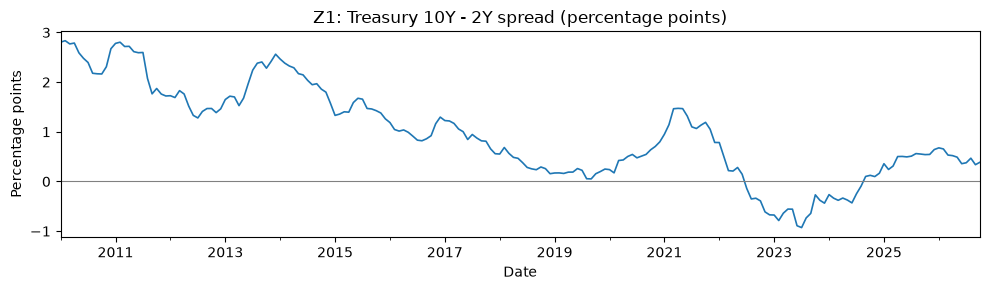

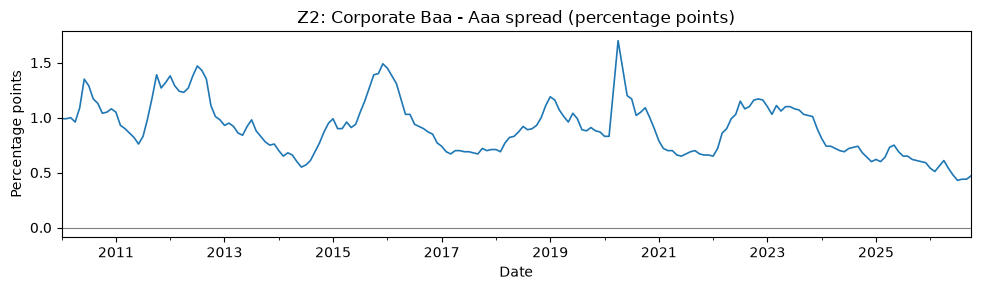

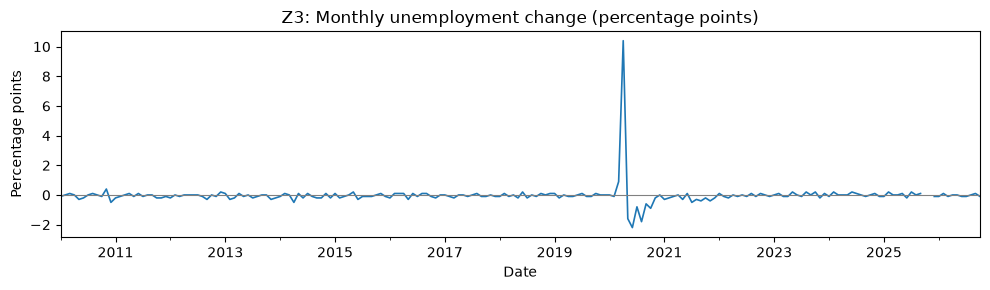

In [15]:
names = {
    "z1_yield_curve": "Z1: Treasury 10Y - 2Y spread (percentage points)",
    "z2_credit_spread": "Z2: Corporate Baa - Aaa spread (percentage points)",
    "z3_unemployment_change": "Z3: Monthly unemployment change (percentage points)",
}
for column, title in names.items():
    fig, ax = plt.subplots(figsize=(10, 3))
    features[column].plot(ax=ax, linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Percentage points")
    ax.axhline(0, color="gray", linewidth=0.8)
    plt.tight_layout()
    plt.show()

In [16]:
levels_path = INTERIM_DIR / "z1_z3_levels_monthly.csv"
features_path = PROCESSED_DIR / "z1_z3_monthly.csv"

monthly.to_csv(levels_path, date_format="%Y-%m-%d")
features.to_csv(features_path, date_format="%Y-%m-%d")

print("Saved:", levels_path.relative_to(ROOT))
print("Saved:", features_path.relative_to(ROOT))
print("Next: run notebooks/02_eda_stationarity_z1_z3.ipynb")

Saved: data/interim/z1_z3_levels_monthly.csv
Saved: data/processed/z1_z3_monthly.csv
Next: run notebooks/02_eda_stationarity_z1_z3.ipynb
